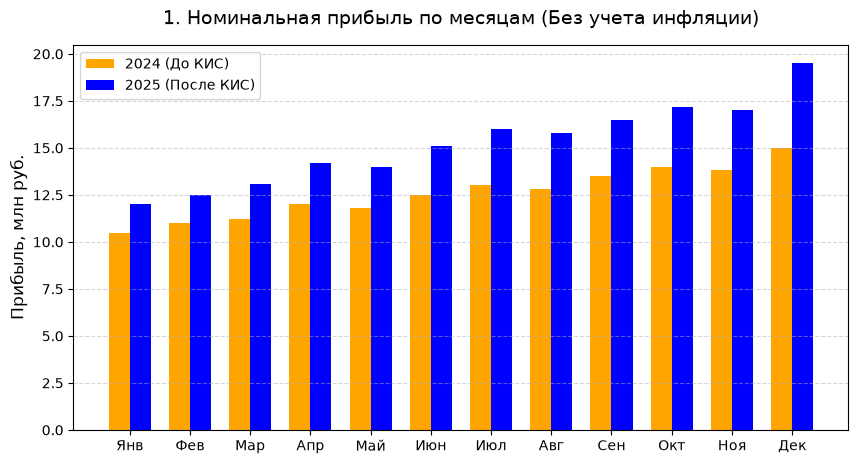

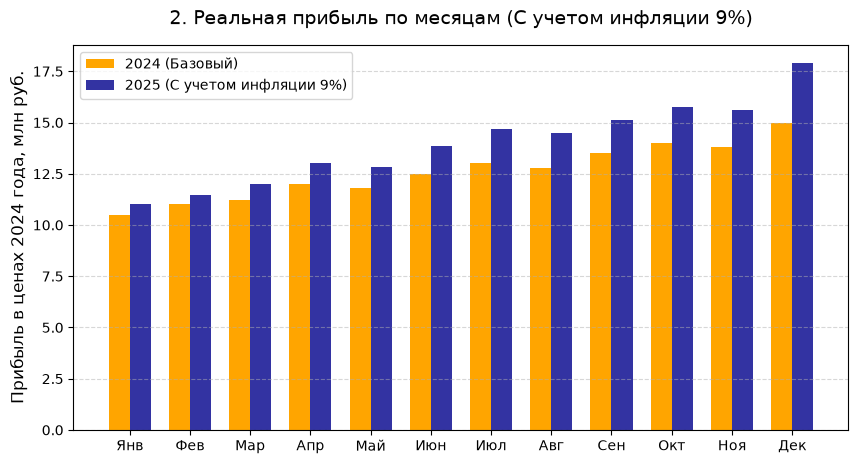

--- Результаты универсального t-теста Стьюдента ---
Размер выборки (n): 12 месяцев (Степени свободы df = 11)
Среднее реальное увеличение прибыли в месяц (x̄): 1.39 млн руб.
Полученное t-значение: 7.142
Динамическое критическое t-значение: ±2.201
p-value (вероятность случайности): 0.000019

ИТОГ: Рост прибыли СТАТИСТИЧЕСКИ ЗНАЧИМ! Внедрение КИС действительно сработало.


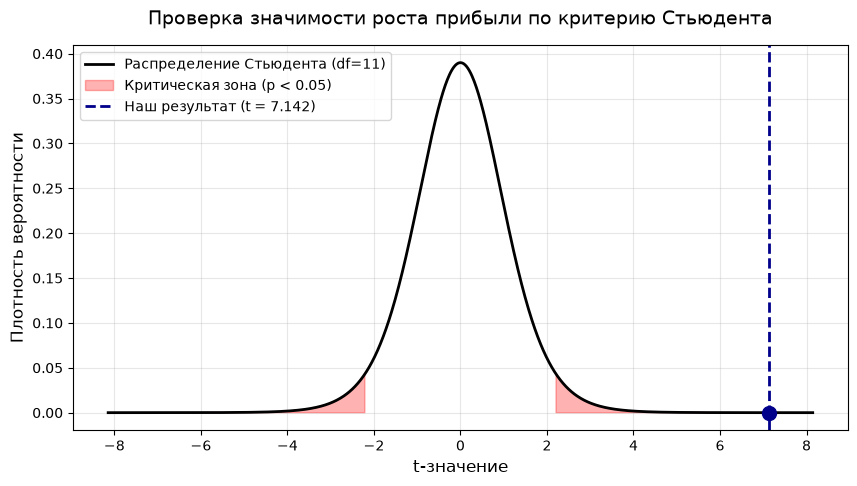

--- Результаты теста Колмогорова-Смирнова ---
Максимальное расстояние D (эмпирическое): 0.417
Критическое значение D (порог значимости): 0.555
p-value (вероятность сходства распределений): 0.255775

ИТОГ: Различия распределений НЕЗНАЧИМЫ. Форма и сдвиг данных могут быть случайными.


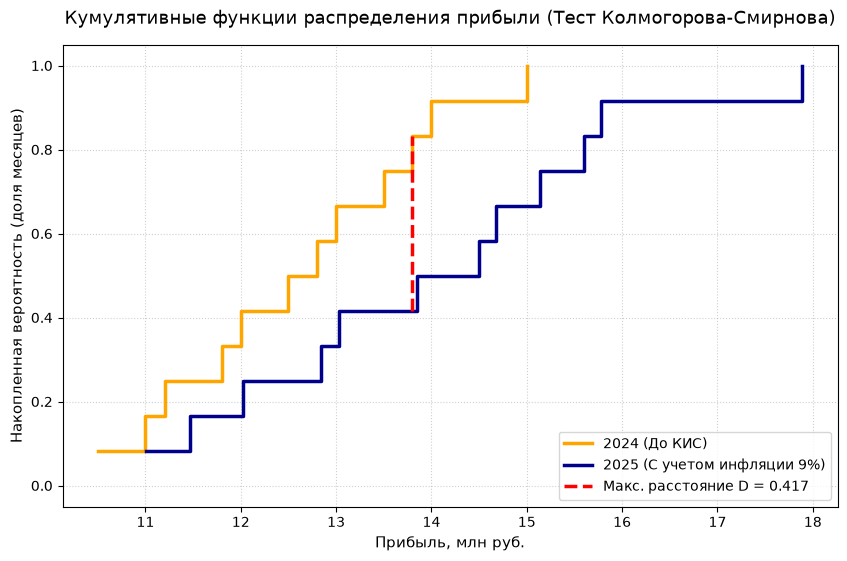

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

months = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
profit_2024 = np.array([10.5, 11.0, 11.2, 12.0, 11.8, 12.5, 13.0, 12.8, 13.5, 14.0, 13.8, 15.0])
profit_2025 = np.array([12.0, 12.5, 13.1, 14.2, 14.0, 15.1, 16.0, 15.8, 16.5, 17.2, 17.0, 19.5])

# Корректировка на инфляцию 9% для 2025 года
profit_2025_adjusted = profit_2025 / 1.09

x = np.arange(len(months))
width = 0.35

#ГИСТОГРАММА 1
plt.figure(figsize=(10, 5))
plt.bar(x - width/2, profit_2024, width, label='2024 (До КИС)', color='orange')
plt.bar(x + width/2, profit_2025, width, label='2025 (После КИС)', color='blue')

plt.title('1. Номинальная прибыль по месяцам (Без учета инфляции)', fontsize=14, pad=15)
plt.xticks(x, months)
plt.ylabel('Прибыль, млн руб.', fontsize=12)
plt.legend(loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

#ГИСТОГРАММА 2
plt.figure(figsize=(10, 5))
plt.bar(x - width/2, profit_2024, width, label='2024 (Базовый)', color='orange')
plt.bar(x + width/2, profit_2025_adjusted, width, label='2025 (С учетом инфляции 9%)', color='darkblue', alpha=0.8)

plt.title('2. Реальная прибыль по месяцам (С учетом инфляции 9%)', fontsize=14, pad=15)
plt.xticks(x, months)
plt.ylabel('Прибыль в ценах 2024 года, млн руб.', fontsize=12)
plt.legend(loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



# 2. Распределение Стьюдента
differences = profit_2025_adjusted - profit_2024
n = len(differences)
df = n - 1

# t = (x̄ – μ₀) / (s / √n)
mean_diff = np.mean(differences)       # x̄
mu_0 = 0                                # μ₀
std_diff = np.std(differences, ddof=1)  # s
t_stat = (mean_diff - mu_0) / (std_diff / np.sqrt(n)) # t-значение

# Находим точное критическое значение для уровня значимости 5% (двусторонний тест)
t_critical = stats.t.ppf(0.975, df)

# вероятность получить такой результат случайно
p_value = stats.t.sf(np.abs(t_stat), df) * 2

print(f"Результаты универсального t-теста Стьюдента")
print(f"Размер выборки (n): {n} месяцев (Степени свободы df = {df})")
print(f"Среднее реальное увеличение прибыли в месяц (x̄): {mean_diff:.2f} млн руб.")
print(f"Полученное t-значение: {t_stat:.3f}")
print(f"Динамическое критическое t-значение: ±{t_critical:.3f}")
print(f"p-value (вероятность случайности): {p_value:.6f}")

if np.abs(t_stat) > t_critical:
    print("\nИТОГ: Рост прибыли СТАТИСТИЧЕСКИ ЗНАЧИМ! Внедрение КИС действительно сработало.")
else:
    print("\nИТОГ: Рост прибыли НЕЗНАЧИМ. Изменения могут быть случайным колебанием.")

# 4. Автоматическая визуализация распределения
plt.figure(figsize=(10, 5))
# Динамически подстраиваем границы графика под полученное t-значение
x_bound = max(6, np.abs(t_stat) + 1)
x_axis = np.linspace(-x_bound, x_bound, 1000)
y_axis = stats.t.pdf(x_axis, df)  # Функция плотности вероятности из scipy

plt.plot(x_axis, y_axis, label=f'Распределение Стьюдента (df={df})', color='black', lw=2)

# Автоматически закрашиваем критические зоны по рассчитанному t_critical
plt.fill_between(x_axis, y_axis, where=(x_axis > t_critical) | (x_axis < -t_critical), color='red', alpha=0.3, label='Критическая зона (p < 0.05)')

# Отмечаем наше полученное t-значение
plt.axvline(t_stat, color='darkblue', linestyle='--', lw=2, label=f'Наш результат (t = {t_stat:.3f})')
plt.scatter(t_stat, 0, color='darkblue', s=100, zorder=5)

plt.title('Проверка значимости роста прибыли по критерию Стьюдента', fontsize=14, pad=15)
plt.xlabel('t-значение', fontsize=12)
plt.ylabel('Плотность вероятности', fontsize=12)
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.show()


#  тест Колмогорова-Смирнова
ks_stat, p_value = stats.ks_2samp(profit_2024, profit_2025_adjusted)

# Вычисление критического значения D для альфа = 0.05 (по классической формуле для малых выборок)
# Для двух выборок размера n1 и n2: c(alpha) * sqrt((n1 + n2) / (n1 * n2)), где c(0.05) ≈ 1.36
n1, n2 = len(profit_2024), len(profit_2025_adjusted)
ks_critical = 1.36 * np.sqrt((n1 + n2) / (n1 * n2))


print(f"--- Результаты теста Колмогорова-Смирнова ---")
print(f"Максимальное расстояние D (эмпирическое): {ks_stat:.3f}")
print(f"Критическое значение D (порог значимости): {ks_critical:.3f}")
print(f"p-value (вероятность сходства распределений): {p_value:.6f}")

if p_value < 0.05:
    print("\nИТОГ: Распределения ПРИНЦИПИАЛЬНО ОТЛИЧАЮТСЯ! Рост прибыли подтвержден критерием K-S.")
else:
    print("\nИТОГ: Различия распределений НЕЗНАЧИМЫ. Форма и сдвиг данных могут быть случайными.")

plt.figure(figsize=(10, 6))
# Графики
x_sorted_24 = np.sort(profit_2024)
y_ecdf_24 = np.arange(1, n1 + 1) / n1

x_sorted_25 = np.sort(profit_2025_adjusted)
y_ecdf_25 = np.arange(1, n2 + 1) / n2

# Для визуализации шагов
plt.step(x_sorted_24, y_ecdf_24, where='post', label='2024 (До КИС)', color='orange', lw=2.5)
plt.step(x_sorted_25, y_ecdf_25, where='post', label='2025 (С учетом инфляции 9%)', color='darkblue', lw=2.5)

# 4. Нахождение и отрисовка точки максимального расхождения D
# Объединяем все точки по оси X для поиска максимума разности по оси Y
x_all = np.concatenate([x_sorted_24, x_sorted_25])
cdf24_all = np.searchsorted(x_sorted_24, x_all, side='right') / n1
cdf25_all = np.searchsorted(x_sorted_25, x_all, side='right') / n2
diff_all = np.abs(cdf24_all - cdf25_all)

max_diff_idx = np.argmax(diff_all)
x_d = x_all[max_diff_idx]
y_24_d = cdf24_all[max_diff_idx]
y_25_d = cdf25_all[max_diff_idx]

# Рисуем красную вертикальную линию, которая символизирует D-статистику
plt.vlines(x_d, min(y_24_d, y_25_d), max(y_24_d, y_25_d), color='red', linestyle='--', lw=2.5, 
           label=f'Макс. расстояние D = {ks_stat:.3f}')

# Настройка внешнего вида графика
plt.title('Кумулятивные функции распределения прибыли (Тест Колмогорова-Смирнова)', fontsize=13, pad=15)
plt.xlabel('Прибыль, млн руб.', fontsize=11)
plt.ylabel('Накопленная вероятность (доля месяцев)', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()